[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L4/BA_L4_dev_daily/BA_L4_dev_daily.ipynb)

# BA_L4_dev_daily: Daily Peg Deviations of USDT, USDC and DAI

*Quantlet of Lecture 4, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Daily deviations from the 1 USD peg, in basis points, of the closing price and of the intraday low of USDT, USDC and DAI, from 1 January 2021 to 23 October 2026, with a band of plus or minus 15 basis points; summary statistics of the deviations. Data: EODHD daily aggregated prices.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Setup: chart style and colours of the slides, and a `save()` helper that puts one legend below the figure.

In [4]:
import matplotlib
import matplotlib.dates as mdates
from scipy import stats

# the slide charts use matplotlib's default sizes with 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 'medium', 'axes.titlesize': 'large', 'axes.linewidth': 0.8,
                     'lines.linewidth': 1.5, 'legend.fontsize': 8})
COL = {'USDT': GREEN, 'USDC': BLUE, 'DAI': GOLD}


def save(fig, name, bottom, ncol=3):
    """One legend for all panels below the plot (as on the slide), then save to OUT_PATH and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

## What the chart shows

The deviation from the peg in basis points (bp; 1 bp = 0.01%) is $d_t = 10^4\,(P_t - 1)$: a price of 0.9990 USD is a deviation of $-10$ bp.
For each coin the chart shows the deviation of the daily close (in colour) and of the intraday low (red, clipped at $-150$ bp so that the scale stays readable), with the $\pm 15$ bp band used later as the depeg threshold.

The closing price shows what remained at the end of the day; the intraday low is the lowest price *reported* in the day, aggregated over venues.

**Data:** EOD Historical Data (EODHD) daily prices, 1 January 2021 to 23 October 2026; earlier years are left out because the aggregate price then includes illiquid venues.

In [5]:
END = '2026-10-23'                      # last day of the lecture sample


def ohlc(sym, start=None, end=END):
    """Daily open, high, low and close from data/market/<sym>.csv."""
    x = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')
    return x.loc[start:end]


dv, lo = {}, {}
for s in ['USDT', 'USDC', 'DAI']:
    x = ohlc(f'{s}-USD.CC', '2021-01-01')
    dv[s], lo[s] = 1e4 * (x['close'] - 1), 1e4 * (x['low'] - 1)     # deviation of the close and of the intraday low, bp
dv, lo = pd.DataFrame(dv), pd.DataFrame(lo)
print(f'daily closes from {dv.index[0].date()} to {dv.index[-1].date()}: {len(dv)} days')

daily closes from 2021-01-01 to 2026-10-23: 2122 days


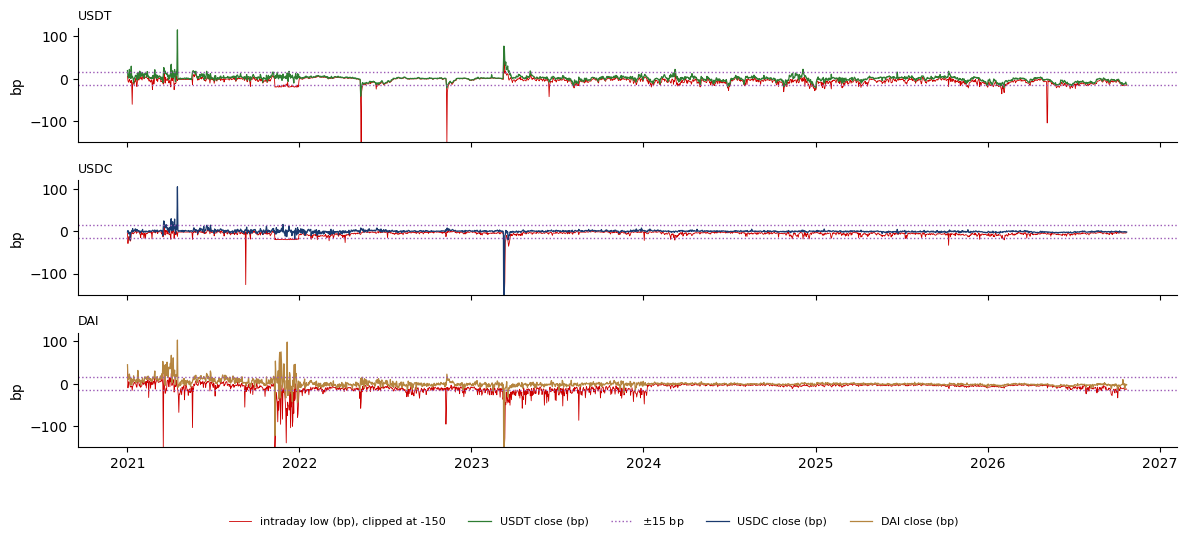

In [6]:
fig, axs = plt.subplots(3, 1, figsize=(12, 5.4), sharex=True)
for ax, s in zip(axs, dv):
    ax.plot(lo.index, lo[s].clip(lower=-150), color=RED, lw=0.6, label=('intraday low (bp), clipped at -150' if s == 'USDT' else None))
    ax.plot(dv.index, dv[s], color=COL[s], lw=0.9, label=f'{s} close (bp)')
    for h in (15, -15):
        ax.axhline(h, color=ETH, ls=':', lw=1, label=('$\\pm$15 bp' if (s == 'USDT' and h == 15) else None))
    ax.set_ylim(-150, 120); ax.set_ylabel('bp'); ax.set_title(s, fontsize=9, loc='left')
save(fig, 'ba_l4_dev_daily', 0.09, ncol=5)

## Key numbers

For each coin: the mean, median and standard deviation (sd) of the daily deviation of the close, its 1% and 99% quantiles, the minimum and its date, the share of days with $|d_t| \geq 15$ bp and $\geq 50$ bp, the deepest intraday low, the share of days whose low was at least 50 bp below the peg, the excess kurtosis (0 for the Normal distribution) and the lag-1 autocorrelation.

In [7]:
rows = {}
for s in dv:
    x, l = dv[s], lo[s]
    rows[s] = {'days': len(x), 'mean (bp)': x.mean(), 'median (bp)': x.median(), 'sd (bp)': x.std(),
               'q 1% (bp)': x.quantile(0.01), 'q 99% (bp)': x.quantile(0.99), 'min close (bp)': x.min(),
               'date of min': x.idxmin().date(), 'max close (bp)': x.max(),
               '% days |d| >= 15': 100 * (x.abs() >= 15).mean(), '% days |d| >= 50': 100 * (x.abs() >= 50).mean(),
               'min intraday low (bp)': l.min(), '% days low <= -50': 100 * (l <= -50).mean(),
               'excess kurtosis': stats.kurtosis(x), 'autocorrelation lag 1': x.autocorr(1)}
pd.DataFrame.from_dict(rows, orient='index').round(2)

,days,mean (bp),median (bp),sd (bp),q 1% (bp),q 99% (bp),min close (bp),date of min,max close (bp),% days |d| >= 15,% days |d| >= 50,min intraday low (bp),% days low <= -50,excess kurtosis,autocorrelation lag 1
USDT,2122,0.46,0.92,7.31,-15.51,21.30,-41.28,2022-05-11,115.30,3.63,0.14,-515.14,0.28,40.02,0.73
USDC,2122,-0.23,-0.21,7.42,-7.57,9.69,-285.00,2023-03-11,104.96,0.66,0.14,-1226.00,0.19,1045.01,0.29
DAI,2122,0.36,-0.77,10.77,-17.18,36.58,-261.31,2023-03-11,103.10,5.23,0.57,-1029.97,1.70,184.80,0.34


**How to read it:** closes stay inside $\pm 15$ bp most of the time; the lows reveal the stress days: May 2022 (Terra) and March 2023 (the failure of Silicon Valley Bank, SVB).
The means lie within $\pm 0.5$ bp, so the peg holds on average and the risk is in the tails. USDC has an excess kurtosis above 1,000 because one weekend dominates its distribution; USDT has the most persistent deviations.